# Proyecto Final IA: Detección de placas y pico y placa en Popayán
Recorrido paso a paso del sistema: detección con OpenCV, lectura con la CNN propia, verificación de pico y placa y asistente.

Ejecute las celdas en orden (Shift + Enter).

In [1]:
import cv2, random, numpy as np
import matplotlib.pyplot as plt
import placas_core as pc
import generador_sintetico as gs
import pico_placa as pyp
from lector_placas import LectorPlacas
from asistente import Asistente

def ver(img, titulo='', gris=False):
    plt.figure(figsize=(8, 5))
    plt.imshow(img if gris else cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap='gray' if gris else None)
    plt.title(titulo); plt.axis('off'); plt.show()

I0000 00:00:1794937658.033861    2254 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794937659.353235    2254 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Imagen de entrada
Por defecto se arma una escena de prueba con una placa sintética. Para usar una foto propia, cambie `RUTA_FOTO`.

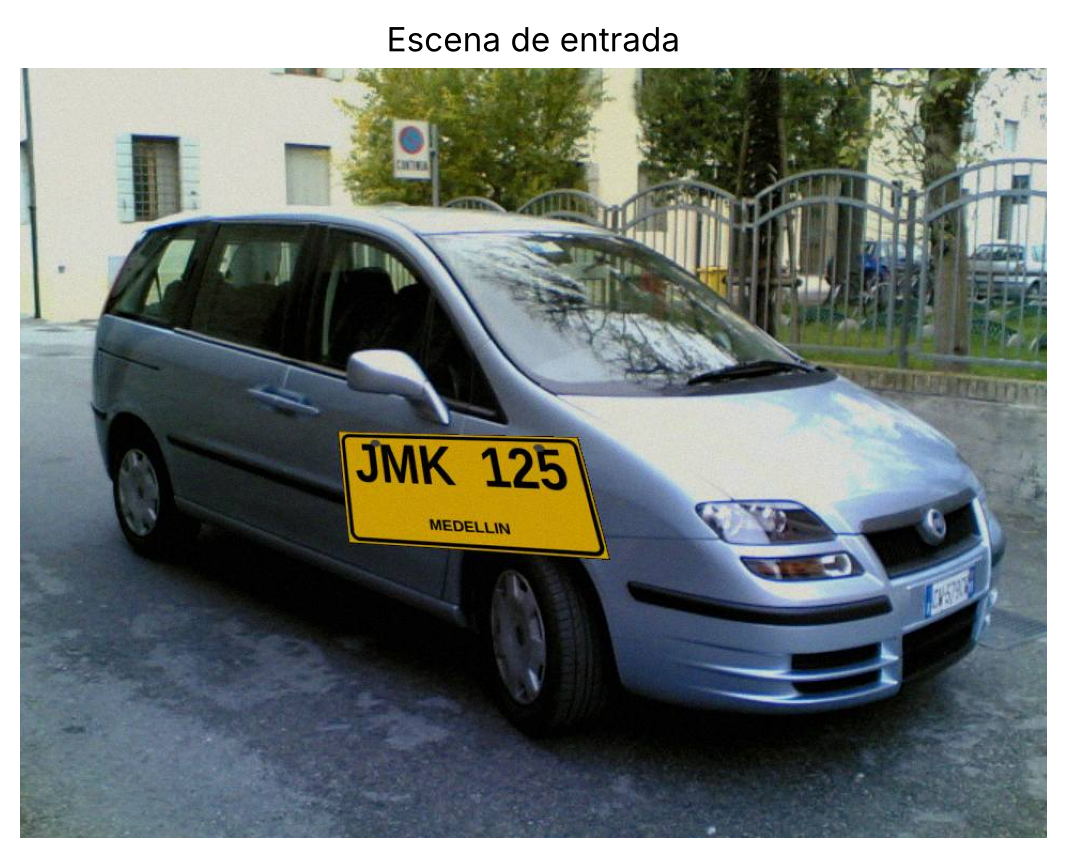

In [2]:
RUTA_FOTO = None   # por ejemplo: 'mi_foto.jpg'
if RUTA_FOTO:
    escena = cv2.imread(RUTA_FOTO)
else:
    rng = random.Random(7)
    fondo = cv2.resize(cv2.imread('fondos/n03770679_minivan.JPEG'), (960, 720))
    escena, _ = gs.componer_escena(fondo, 'JMK125', rng, ancho_placa=230)
ver(escena, 'Escena de entrada')

## 2. Detección con OpenCV
Máscara amarilla en HSV + cuadriláteros por bordes, verificados por color y forma.

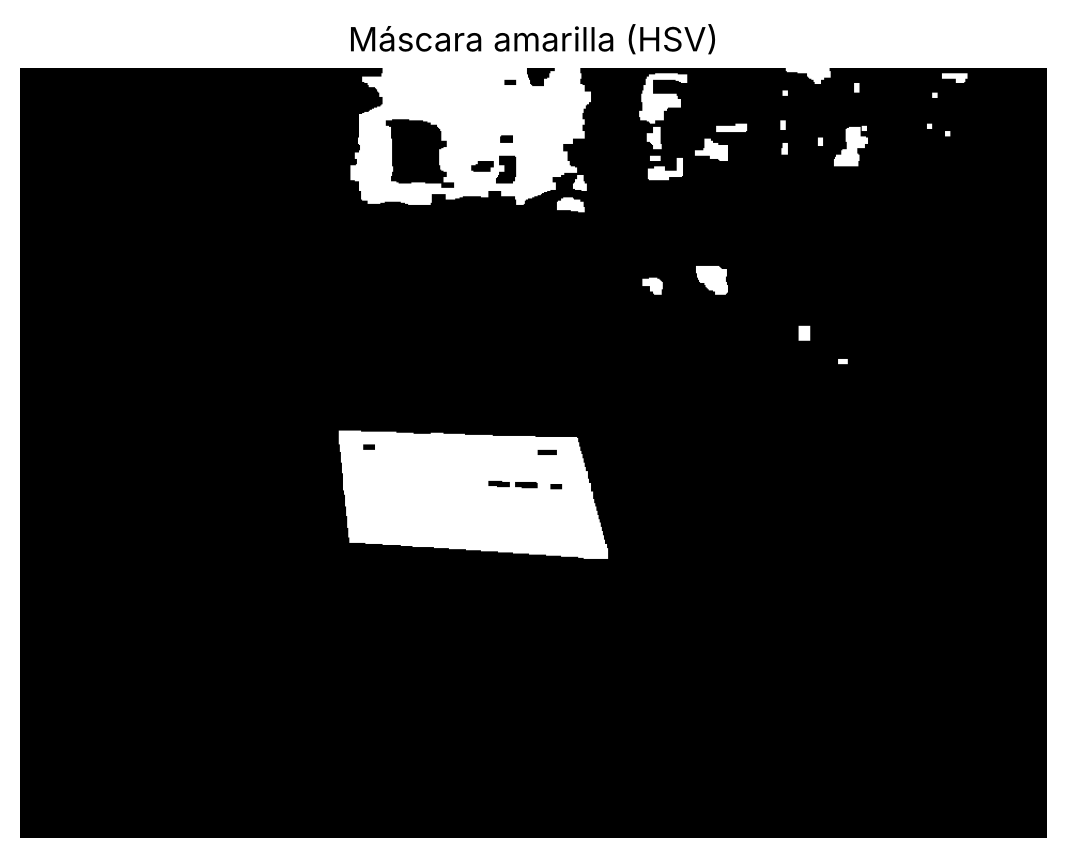

2 candidato(s); puntajes: [0.81, 0.59]


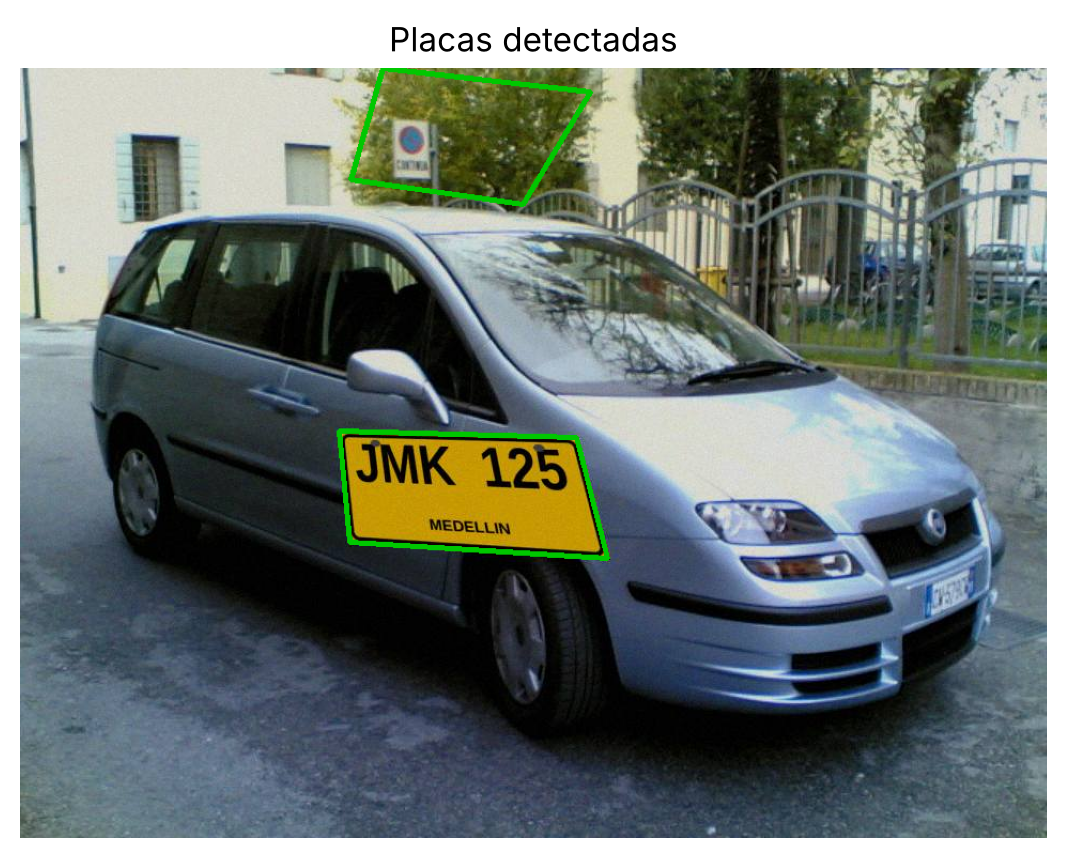

In [3]:
ver(pc.mascara_amarilla(escena), 'Máscara amarilla (HSV)', gris=True)
candidatos = pc.detectar_placas(escena)
vis = escena.copy()
for c in candidatos:
    cv2.polylines(vis, [c['esquinas'].astype(np.int32)], True, (0, 200, 0), 3)
print(len(candidatos), 'candidato(s); puntajes:', [round(c['puntaje'], 2) for c in candidatos])
ver(vis, 'Placas detectadas')

## 3. Rectificación y segmentación

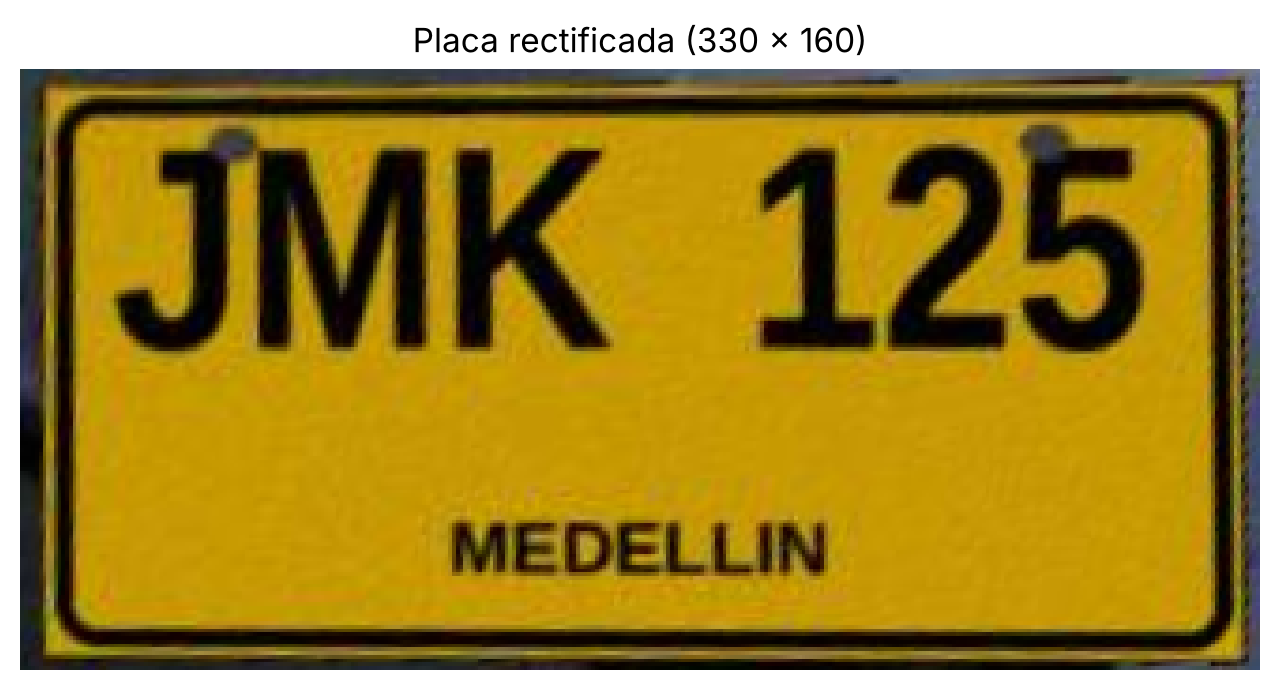

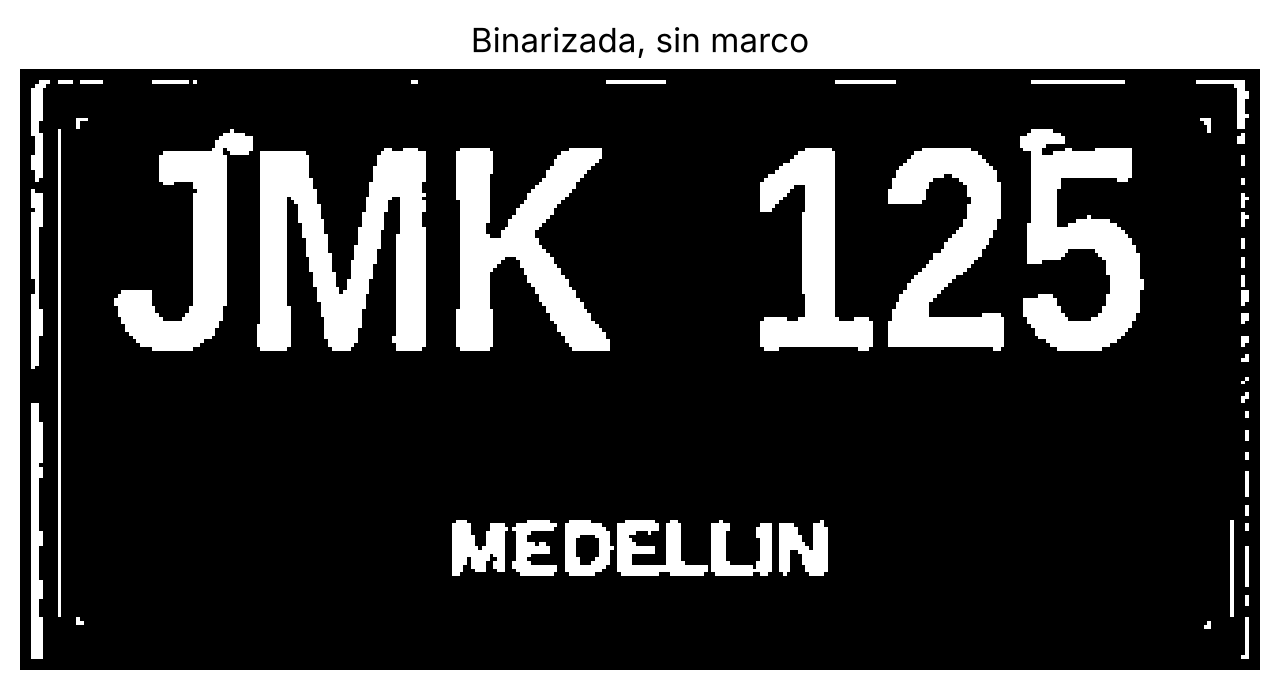

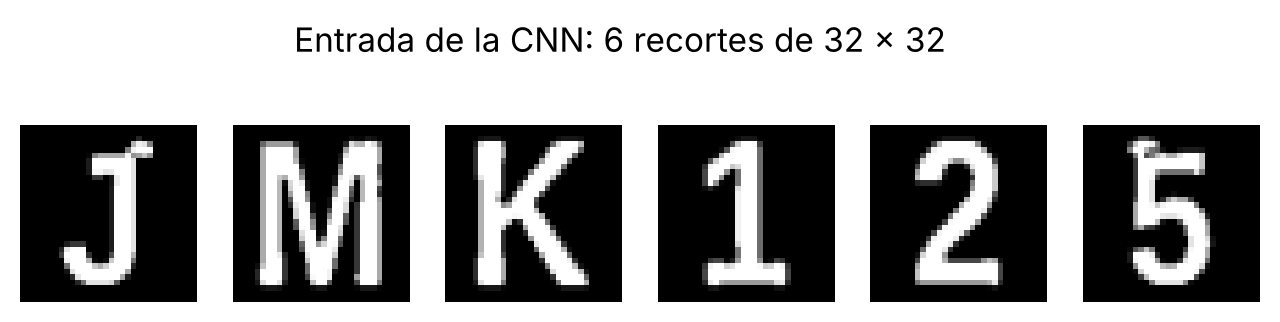

In [4]:
placa = pc.rectificar(escena, candidatos[0]['esquinas'])
recortes, cajas, binaria = pc.segmentar_caracteres(placa, devolver_cajas=True)
ver(placa, 'Placa rectificada (330 x 160)')
ver(binaria, 'Binarizada, sin marco', gris=True)
plt.figure(figsize=(8, 2))
for i, r in enumerate(recortes):
    plt.subplot(1, 6, i + 1); plt.imshow(r, cmap='gray'); plt.axis('off')
plt.suptitle('Entrada de la CNN: 6 recortes de 32 x 32'); plt.show()

## 4. Lectura con la CNN propia

In [5]:
lector = LectorPlacas()
lector.modelo.summary()
texto, confianza, probs = lector.reconocer_caracteres(recortes)
print('Placa leída:', texto, '| confianza mínima por carácter:', round(confianza, 3))

Model: "CNN_caracteres_placas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,464,206 (9.40 MB)

 Trainable params: 820,932 (3.13 MB)

 Non-trainable params: 1,408 (5.50 KB)

 Optimizer params: 1,641,866 (6.26 MB)

Placa leída: JMK125 | confianza mínima por carácter: 0.891


## 5. Pico y placa en Popayán

In [6]:
print(pyp.resumen_reglas())
print()
print(pyp.verificar(texto)['explicacion'])
print('Próximos días con restricción:', [pyp.fecha_texto(d) for d in pyp.proximos_dias(texto)])

Pico y placa en Popayán (Segundo semestre de 2026 (con sanciones desde el 6 de julio de 2026)).
Aplica a: Carros particulares y motocicletas (último dígito de la placa).
Horario: 07:00 a 20:00, de lunes a viernes; no aplica sábados, domingos ni festivos.
  Lunes      placas terminadas en 9 y 0
  Martes     placas terminadas en 1 y 2
  Miércoles  placas terminadas en 3 y 4
  Jueves     placas terminadas en 5 y 6
  Viernes    placas terminadas en 7 y 8
Sanción: Infracción C.14 del Código Nacional de Tránsito: multa e inmovilización del vehículo.
Nota: Verificar el horario con la Secretaría de Tránsito: en 2026 algunos medios publicaron 7:00 a. m. - 8:00 p. m. y otros 8:00 a. m. - 6:00 p. m.

La placa JMK125 (termina en 5) puede circular el martes 17 de noviembre de 2026. Ese día la restricción es para placas terminadas en 1 y 2.
Próximos días con restricción: ['jueves 19 de noviembre de 2026', 'jueves 26 de noviembre de 2026', 'jueves 3 de diciembre de 2026']


## 6. Asistente
Con la variable de entorno `ANTHROPIC_API_KEY` usa Claude (modo generativo); sin ella, el modo de respaldo.

In [7]:
asistente = Asistente()
print('Modo:', asistente.modo)
for q in [f'¿La placa {texto} puede salir hoy?', '¿Qué placas tienen pico y placa el viernes?', '¿Cuánto es la multa?']:
    print('Usted:', q)
    print('Asistente:', asistente.preguntar(q), '\n')

Modo: respaldo sin internet
Usted: ¿La placa JMK125 puede salir hoy?
Asistente: La placa JMK125 (termina en 5) puede circular el martes 17 de noviembre de 2026. Ese día la restricción es para placas terminadas en 1 y 2. Próximos días con restricción: jueves 19 de noviembre de 2026, jueves 26 de noviembre de 2026, jueves 3 de diciembre de 2026. 

Usted: ¿Qué placas tienen pico y placa el viernes?
Asistente: El viernes 20 de noviembre de 2026 tienen pico y placa las placas terminadas en 7 y 8, de 07:00 a 20:00. 

Usted: ¿Cuánto es la multa?
Asistente: Infracción C.14 del Código Nacional de Tránsito: multa e inmovilización del vehículo. Hay excepciones (por ejemplo, vehículos de emergencia o de personas con discapacidad, Leyes 2623 y 2624 de 2026). Consulte la lista completa con la Secretaría de Tránsito y Transporte de Popayán. 



## 7. Tiempo real
En Spyder o en una terminal: `python app_tiempo_real.py` (cámara) o `python app_tiempo_real.py resultados/video_demo.mp4`. La ventana de video no se muestra dentro de Jupyter.